# We load data from the Eurocrops dataset. First, I will chooose one region and year. 

In [45]:
#set working directory to project root
from pathlib import Path
import sys

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

print(project_root)

/Users/henristaehelin/Desktop/UZH/SDS320/project


In [46]:
from pathlib import Path

project_dir = Path("..").resolve()

images_dir = project_dir / "data/raw/imagery/sentinel2"
masks_dir = project_dir / "data/raw/raster"

print("Project:", project_dir)
print("Images exist:", images_dir.exists())
print("Masks exist:", masks_dir.exists())

Project: /Users/henristaehelin/Desktop/UZH/SDS320/project
Images exist: True
Masks exist: True


### 1. Data load. I chose to load data from germany in 2023. 

In [47]:
import geopandas as gpd
germany_2023 = gpd.read_parquet("../data/raw/vectors/dea_2023.parquet")
germany_2023.head(5)

,cropfield,original_code,off_id,off_area,area_ha,geometry
0,713879,575,7158611,0.1413,0.141340,"MULTIPOLYGON (((4075066.904 3118777.11, 407491..."
1,709592,66,7103747,0.0777,0.077780,"MULTIPOLYGON (((4061747.758 3135219.228, 40615..."
2,711311,994,7060421,0.0053,0.005314,"MULTIPOLYGON (((4242608.123 3250820.547, 42426..."
3,713404,996,7131892,0.0639,0.064025,"MULTIPOLYGON (((4229259.343 3207621.8, 4229293..."
4,713622,860,7135902,2.8559,2.857417,"MULTIPOLYGON (((4142676.982 3210526.616, 41427..."


We have the cropfield number, the geometry, but what about the crop type label?

Could that be original_code?

In [48]:
import pandas as pd
crop_names = pd.read_csv("../data/raw/Eurocrops.csv")
crop_names.head(5)

,nuts,original_code,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
0,at,10001,NICHT DEFINIERT,not defined,3390000000,not_known_and_other,0,No specified use
1,at,105,KÖRNERMAIS,GRAIN CORN,3310106000,maize_corn_popcorn,6,Harvested as Grains
2,at,106,MAIS CORN-COB-MIX (CCM),CORN CORN-COB-MIX (CCM),3310106000,maize_corn_popcorn,0,No specified use
3,at,107,ZUCKERMAIS,SUGAR CORN,3310106000,maize_corn_popcorn,0,No specified use
4,at,109,SILOMAIS,SILO CORN,3310106000,maize_corn_popcorn,3,Fodder/Forage


This file has all the codes for each country. "nuts" is the country tag. So for italy it would be iti1. We want the table of country specific crop codes of only italy. 

In [49]:
germany_cropnames = crop_names[crop_names["nuts"] == "dea"] #select only rows with german codes
germany_cropnames.head(5)

,nuts,original_code,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
1809,dea,10222,Dicke Bohne,Broad bean,3310201010,beans,0,No specified use
1810,dea,112,Winterdurum (Hartweizen),Winter hard wheat / durum,3310102001,winter_durum_hard_wheat,0,No specified use
1811,dea,113,Sommerdurum (Hartweizen),Summer durum wheat / durum,3310102002,spring_durum_hard_wheat,0,No specified use
1812,dea,114,Winter-Dinkel,Winter spelt,3310110001,winter_spelt,0,No specified use
1813,dea,115,Winterweichweizen,Winter soft wheat,3310101001,winter_common_soft_wheat,0,No specified use


Merge them with the german crop dataset, now we will have the polygons with the labels. 
#### **Consider generalizing this process into a python script that we can call upon, this would allow us to efficiently combine multiple vector datasets from different countries into one.**

In [50]:
germany_2023 = germany_2023.merge(
    germany_cropnames,
    on=["original_code"],
    how="left")
germany_2023.head(5)

,cropfield,original_code,off_id,off_area,area_ha,geometry,nuts,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
0,713879,575,7158611,0.1413,0.141340,"MULTIPOLYGON (((4075066.904 3118777.11, 407491...",dea,Blühfläche (AUM-Altmaßnahme,Flowering area (AUM-old measure),3310800000,flowers_ornamental_plants,0,No specified use
1,709592,66,7103747,0.0777,0.077780,"MULTIPOLYGON (((4061747.758 3135219.228, 40615...",dea,Kond.-Brache (aktive Begrünun,Fallow land (active greening),3311100000,fallow_land_not_crop,0,No specified use
2,711311,994,7060421,0.0053,0.005314,"MULTIPOLYGON (((4242608.123 3250820.547, 42426...",dea,Unbefestigte Mieten DGL,Unfixed rents permanent grass land,3320100000,permanent_grassland,0,No specified use
3,713404,996,7131892,0.0639,0.064025,"MULTIPOLYGON (((4229259.343 3207621.8, 4229293...",dea,Unbefestigte Mieten AL,unfixed rents AL,3390000000,not_known_and_other,0,No specified use
4,713622,860,7135902,2.8559,2.857417,"MULTIPOLYGON (((4142676.982 3210526.616, 41427...",dea,Spargel,asparagus,3310706000,asparagus,0,No specified use


We now have polygons and labels. We will use hcat4_name as this is the harmonized label across multiple countries.

Lets also see how many unique crops there are. 

In [51]:
#see number of unique crops
print(germany_2023["hcat4_name"].nunique())
print(germany_2023["hcat4_code"].nunique()) #making sure number of unique names and codes line up

173
173


#### Thats a lot of crop types, I think its easier to learn less first. Lets see what types of crops there are.

In [52]:
print(germany_2023["hcat4_name"].unique())

['flowers_ornamental_plants' 'fallow_land_not_crop' 'permanent_grassland'
 'not_known_and_other' 'asparagus' 'potatoes' 'ericaceae_heather'
 'winter_common_soft_wheat' 'onions' 'winter_barley' 'spring_barley'
 'spring_oats' 'temporary_grassland' 'rhubarb' 'berries_berry_species'
 'clover' 'unmaintained' 'orchards_fruits' 'winter_durum_hard_wheat'
 'cereal' 'beans' 'winter_rapeseed_rape' 'conifers' 'winter_rye'
 'winter_triticale' 'miscanthus_silvergrass' 'sugar_beet'
 'alfalfa_lucerne' 'maize_corn_popcorn' 'fresh_vegetables' 'arable_crops'
 'brassicaceae_cruciferae' 'strawberries' 'sunflower'
 'winter_mixed_grains' 'winter_spelt'
 'aromatic_medicinal_culinary_plants_spices_herbs'
 'spring_common_soft_wheat' 'spring_triticale' 'peas' 'celery' 'spinach'
 'cucumber_pickle' 'winter_oats' 'lupins' 'pumpkin_squash_gourd'
 'carrots_daucus' 'seed_seedlings' 'nurseries_nursery'
 'permanent_crops_perennial' 'poaceae_grasses' 'radish' 'peony_peonies'
 'hazelnuts_hazel' 'elymus' 'edelweiss' 'other

#### There are a lot of crops that are not relevant or may be to difficult to identify. I made a list. 
fallow_land_not_crop, not_known_and_other, unmaintained, seed_seedlings, nurseries_nursery, poaceae_grasses, other_flowers_ornamental_plants, flowers_ornamental_plants, other_aromatic_medicinal_culinary_plants_spices_herbs, afforestation_reforestation, spring_mixed_grains, other_industrial_crops, other_poaceae_grasses, other_arable_land_crops

This is 14 types that don't work, this still leaves me with 159 crop types. I think it might make most sense to pick 30 and then see from there. 

#### Instead lets choose 30 different crop types. 

In [53]:
# Check the number of polygons per crop type
crop_counts = germany_2023["hcat4_name"].value_counts()

subset = [
    "winter_common_soft_wheat", "winter_barley", "spring_barley", "winter_rapeseed_rape",
    "maize_corn_popcorn", "sugar_beet", "potatoes", "winter_rye", "winter_triticale",
    "winter_oats", "spring_oats", "winter_spelt", "winter_durum_hard_wheat", "spring_common_soft_wheat",
    "winter_mixed_grains", "sunflower", "soy_soybeans", "peas", "beans", "lupins",
    "temporary_grassland", "permanent_grassland", "alfalfa_lucerne", "clover",
    "winter_emmer", "buckwheat", "miscanthus_silvergrass", "asparagus", "strawberries", "carrots_daucus",
]

print(crop_counts.reindex(subset, fill_value=0))

hcat4_name
winter_common_soft_wheat     69959
winter_barley                43410
spring_barley                 3529
winter_rapeseed_rape         16689
maize_corn_popcorn           91195
sugar_beet                   13079
potatoes                     11308
winter_rye                   15277
winter_triticale             17376
winter_oats                    536
spring_oats                   3289
winter_spelt                   808
winter_durum_hard_wheat        685
spring_common_soft_wheat      1320
winter_mixed_grains             85
sunflower                      409
soy_soybeans                   220
peas                          2117
beans                         3072
lupins                         250
temporary_grassland          28327
permanent_grassland         294894
alfalfa_lucerne               1506
clover                        5298
winter_emmer                    28
buckwheat                       34
miscanthus_silvergrass         790
asparagus                     1672
strawberr

#### Lets create a subset from these crop types, from this we will choose scenes that have at least 10 different crop types.

In [54]:
# Keep only the 30 selected crop types
reduced_crops = germany_2023[
    germany_2023["hcat4_name"].isin(subset)
].copy()

print("Original polygons:", len(germany_2023))
print("Subset polygons:", len(reduced_crops))
print("Crop types present:", reduced_crops["hcat4_name"].nunique())

reduced_crops.head(5)

Original polygons: 748208
Subset polygons: 629482
Crop types present: 30


,cropfield,original_code,off_id,off_area,area_ha,geometry,nuts,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
2,711311,994,7060421,0.0053,0.005314,"MULTIPOLYGON (((4242608.123 3250820.547, 42426...",dea,Unbefestigte Mieten DGL,Unfixed rents permanent grass land,3320100000,permanent_grassland,0,No specified use
4,713622,860,7135902,2.8559,2.857417,"MULTIPOLYGON (((4142676.982 3210526.616, 41427...",dea,Spargel,asparagus,3310706000,asparagus,0,No specified use
6,714367,602,7209215,0.6296,0.629910,"MULTIPOLYGON (((4115046.183 3117774.226, 41151...",dea,Kartoffeln,potatoes,3310300000,potatoes,0,No specified use
9,716260,115,7061460,2.4301,2.432082,"MULTIPOLYGON (((4243063.131 3249725.238, 42432...",dea,Winterweichweizen,Winter soft wheat,3310101001,winter_common_soft_wheat,0,No specified use
11,716867,115,7132898,2.0211,2.022715,"MULTIPOLYGON (((4242002.866 3240369.434, 42420...",dea,Winterweichweizen,Winter soft wheat,3310101001,winter_common_soft_wheat,0,No specified use


#### Now we want to select areas that have at least 10 different crop types. 

In [55]:
import geopandas as gpd
import numpy as np
from shapely.geometry import box

# Use the filtered crop dataset
germany_utm = reduced_crops.to_crs("EPSG:32632")

minx, miny, maxx, maxy = germany_utm.total_bounds #sets the bounds the polygons based on germany
cell_size = 2000  # 2 km, considering 10m is pixel this makes an area of 200 by 200 pixels

x_coords = np.arange(
    np.floor(minx / cell_size) * cell_size,
    maxx,
    cell_size
)
y_coords = np.arange(
    np.floor(miny / cell_size) * cell_size,
    maxy,
    cell_size
)

grid = gpd.GeoDataFrame(
    {"area_id": range(len(x_coords) * len(y_coords))},
    geometry=[
        box(x, y, x + cell_size, y + cell_size)
        for x in x_coords
        for y in y_coords
    ],
    crs=germany_utm.crs
)

# Count crop types intersecting each grid cell
joined = gpd.sjoin(
    germany_utm[["hcat4_name", "geometry"]],
    grid[["area_id", "geometry"]],
    how="inner",
    predicate="intersects"
)

crop_counts = (
    joined.groupby("area_id")["hcat4_name"]
    .nunique()
    .rename("n_crop_types")
)

grid = grid.join(crop_counts, on="area_id")
grid["n_crop_types"] = grid["n_crop_types"].fillna(0).astype(int)

# Find areas with at least 10 different crop types
candidates = (
    grid[grid["n_crop_types"] >= 10]
    .sort_values("n_crop_types", ascending=False)
    .copy()
)

print("Suitable areas found:", len(candidates))
display(candidates[["area_id", "n_crop_types"]].head(20))

Suitable areas found: 3327


,area_id,n_crop_types
4699,4699,19
5192,5192,19
3712,3712,19
10643,10643,19
3730,3730,18
12763,12763,18
14336,14336,18
2848,2848,18
3369,3369,18
2366,2366,18


We have lots of suitable areas, lets select the 5 with the most crop types. 

In [56]:
selected = []

for _, candidate in candidates.iterrows():
    if all(
        not candidate.geometry.intersects(existing.geometry)
        for existing in selected
    ):
        selected.append(candidate)

    if len(selected) == 5:
        break

selected_areas = gpd.GeoDataFrame(
    selected,
    crs=grid.crs
)

print(f"Selected {len(selected_areas)} areas")
display(selected_areas[["area_id", "n_crop_types"]])

Selected 5 areas


,area_id,n_crop_types
4699,4699,19
5192,5192,19
3712,3712,19
10643,10643,19
3730,3730,18


#### We now have 5 suitable 2 by 2 km areas that we can use. Lets take one and combine it with Sentinel 2 data. 

### 2. We want to combine it now with the Sentinel-2 raster data and load them together. 

In [25]:
reduced_crops.crs
#first check CRS

<Projected CRS: EPSG:3035>
Name: ETRS89-extended / LAEA Europe
Axis Info [cartesian]:
- Y[north]: Northing (metre)
- X[east]: Easting (metre)
Area of Use:
- name: Europe - European Union (EU) countries and candidates. Europe - onshore and offshore: Albania; Andorra; Austria; Belgium; Bosnia and Herzegovina; Bulgaria; Croatia; Cyprus; Czechia; Denmark; Estonia; Faroe Islands; Finland; France; Germany; Gibraltar; Greece; Hungary; Iceland; Ireland; Italy; Kosovo; Latvia; Liechtenstein; Lithuania; Luxembourg; Malta; Monaco; Montenegro; Netherlands; North Macedonia; Norway including Svalbard and Jan Mayen; Poland; Portugal including Madeira and Azores; Romania; San Marino; Serbia; Slovakia; Slovenia; Spain including Canary Islands; Sweden; Switzerland; Türkiye (Turkey); United Kingdom (UK) including Channel Islands and Isle of Man; Vatican City State.
- bounds: (-35.58, 24.6, 44.83, 84.73)
Coordinate Operation:
- name: Europe Equal Area 2001
- method: Lambert Azimuthal Equal Area
Datum: Eur

In [26]:
selected_wgs84 = selected_areas.to_crs("EPSG:4326")

print(selected_wgs84.crs)

EPSG:4326


In [27]:
from pystac_client import Client
import planetary_computer as pc

pc_catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

items_by_area = {}

for _, area in selected_wgs84.iterrows():
    area_id = area["area_id"]
    geometry = area.geometry.__geo_interface__

    search = pc_catalog.search(
        collections=["sentinel-2-l2a"],
        intersects=geometry,
        datetime="2023-01-01/2023-12-31",
        query={"eo:cloud_cover": {"lt": 20}},
        max_items=10,
    )

    items = list(search.items())
    items_by_area[area_id] = items

    print(f"Area {area_id}: found {len(items)} scenes")

Area 4699: found 10 scenes
Area 5192: found 10 scenes
Area 3712: found 10 scenes
Area 10643: found 10 scenes
Area 3730: found 10 scenes


##### Select the best scenes (least cloud cover) for each area. 

In [28]:
import planetary_computer as pc

best_items = {}

for area_id, items in items_by_area.items():

    if not items:
        print(f"No Sentinel-2 scenes found for area {area_id}")
        continue

    items_sorted = sorted(
        items,
        key=lambda item: item.properties.get("eo:cloud_cover", 999),
    )
# looks through the scenes and chooses the one with the least cloud cover calls it s2_item
    s2_item = pc.sign(items_sorted[0])
    best_items[area_id] = s2_item
# this is then added to the dictionary of best_items
    print(f"\nArea: {area_id}")
    print("Selected item:", s2_item.id)
    print("Date:", s2_item.datetime)
    print(
        "Cloud cover:",
        round(s2_item.properties.get("eo:cloud_cover", 999), 2),
    )

    print("Useful assets:")
    for key in ["B02", "B03", "B04", "B08", "SCL", "visual"]:
        if key in s2_item.assets:
            print(key, "-", s2_item.assets[key].title)


Area: 4699
Selected item: S2B_MSIL2A_20230911T102609_R108_T32ULB_20230911T183201
Date: 2023-09-11 10:26:09.024000+00:00
Cloud cover: 0.0
Useful assets:
B02 - Band 2 - Blue - 10m
B03 - Band 3 - Green - 10m
B04 - Band 4 - Red - 10m
B08 - Band 8 - NIR - 10m
SCL - Scene classfication map (SCL)
visual - True color image

Area: 5192
Selected item: S2B_MSIL2A_20230911T102609_R108_T32ULB_20230911T183201
Date: 2023-09-11 10:26:09.024000+00:00
Cloud cover: 0.0
Useful assets:
B02 - Band 2 - Blue - 10m
B03 - Band 3 - Green - 10m
B04 - Band 4 - Red - 10m
B08 - Band 8 - NIR - 10m
SCL - Scene classfication map (SCL)
visual - True color image

Area: 3712
Selected item: S2B_MSIL2A_20230911T102609_R108_T32ULB_20230911T183201
Date: 2023-09-11 10:26:09.024000+00:00
Cloud cover: 0.0
Useful assets:
B02 - Band 2 - Blue - 10m
B03 - Band 3 - Green - 10m
B04 - Band 4 - Red - 10m
B08 - Band 8 - NIR - 10m
SCL - Scene classfication map (SCL)
visual - True color image

Area: 10643
Selected item: S2A_MSIL2A_2023090

##### Save the bands for each scene in each area.

In [29]:
from pathlib import Path
from scripts.Raster_helper_functions import save_multiband_subset

output_dir = Path("../data/raw/imagery/sentinel2")
output_dir.mkdir(parents=True, exist_ok=True)

s2_paths = {}

for _, area in selected_wgs84.iterrows():

    area_id = area["area_id"]

    if area_id not in best_items:
        continue

    s2_item = best_items[area_id]

    # Bounding box in WGS84: [min_lon, min_lat, max_lon, max_lat]
    bbox_wgs84 = list(area.geometry.bounds)

    output_path = output_dir / f"germany_2023_area_{area_id}.tif"

    s2_path = save_multiband_subset(
        item=s2_item,
        asset_keys=[
            "B02",  # Blue
            "B03",  # Green
            "B04",  # Red
            "B08",  # Near-infrared
        ],
        bbox_wgs84=bbox_wgs84,
        output_path=output_path,
    )

    s2_paths[area_id] = s2_path

print("\nDownloaded areas:", len(s2_paths))

Saved: ../data/raw/imagery/sentinel2/germany_2023_area_4699.tif (0.26 MB)
Saved: ../data/raw/imagery/sentinel2/germany_2023_area_5192.tif (0.26 MB)
Saved: ../data/raw/imagery/sentinel2/germany_2023_area_3712.tif (0.26 MB)
Saved: ../data/raw/imagery/sentinel2/germany_2023_area_10643.tif (0.25 MB)
Saved: ../data/raw/imagery/sentinel2/germany_2023_area_3730.tif (0.26 MB)

Downloaded areas: 5


In [30]:
import leafmap
import rasterio

maps = {}

for area_id, raster_path in s2_paths.items():

    # Get the crop fields for this selected area
    area = selected_areas.loc[
        selected_areas["area_id"] == area_id
    ].to_crs(reduced_crops.crs)

    crop_fields = gpd.clip(
        reduced_crops,
        area
    )

    m = leafmap.Map(height="500px")
    m.add_basemap("Esri.WorldImagery")

    # True-colour RGB (B04, B03, B02)
    m.add_raster(
        str(raster_path),
        indexes=[3, 2, 1],
        layer_name="Sentinel-2 True Color",
    )

    # False-colour composite (B08, B04, B03)
    m.add_raster(
        str(raster_path),
        indexes=[4, 3, 2],
        layer_name="Sentinel-2 False Color",
    )

    m.add_gdf(
        crop_fields,
        layer_name="German Crop Fields",
    )

    m.add_layer_control()
    maps[area_id] = m

    print(f"Map for area {area_id}")
    display(m)

Map for area 4699


Map(center=[50.7770925, 6.971693], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title',…

Map for area 5192


Map(center=[50.7969865, 7.084332], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title',…

Map for area 3712


Map(center=[50.719008, 6.747504], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', …

Map for area 10643


Map(center=[51.512167, 8.32272], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', '…

Map for area 3730


Map(center=[51.042525999999995, 6.7318305], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_i…

## 3. Data Preprocessing

While we can visually confirm that the polygons match up onto the satellite data. We want to check crs of both vector and raster data to make sure they are the same. Also we can check the bounds while we are at it.

In [31]:
import geopandas as gpd
import rasterio
from shapely.geometry import box

for area_id, raster_path in s2_paths.items():

    # Find the matching area
    area = selected_areas.loc[selected_areas["area_id"] == area_id]

    if area.empty:
        print(f"No matching area found for Area {area_id}")
        continue

    # Open raster and retrieve its information
    with rasterio.open(raster_path) as src:
        raster_crs = src.crs
        raster_bounds = src.bounds
        raster_extent = box(*raster_bounds)

    # Reproject the area to the raster CRS for a fair bounds comparison
    area_in_raster_crs = area.to_crs(raster_crs)
    vector_bounds = area_in_raster_crs.geometry.iloc[0].bounds

    print(f"\n{'=' * 50}")
    print(f"Area ID: {area_id}")
    print("Raster path:", raster_path)
    print("Raster CRS:", raster_crs)
    print("Original vector CRS:", area.crs)
    print("Raster bounds:", raster_bounds)
    print("Vector bounds (raster CRS):", vector_bounds)
    print("Raster overlaps area:", raster_extent.intersects(
        area_in_raster_crs.geometry.iloc[0]
    ))


Area ID: 4699
Raster path: ../data/raw/imagery/sentinel2/germany_2023_area_4699.tif
Raster CRS: EPSG:32632
Original vector CRS: EPSG:32632
Raster bounds: BoundingBox(left=355944.77592704573, bottom=5625998.516700741, right=358054.77592704573, top=5627998.516700741)
Vector bounds (raster CRS): (356000.0, 5626000.0, 358000.0, 5628000.0)
Raster overlaps area: True

Area ID: 5192
Raster path: ../data/raw/imagery/sentinel2/germany_2023_area_5192.tif
Raster CRS: EPSG:32632
Original vector CRS: EPSG:32632
Raster bounds: BoundingBox(left=363947.8053339127, bottom=5627998.677280025, right=366047.8053339127, top=5629998.677280025)
Vector bounds (raster CRS): (364000.0, 5628000.0, 366000.0, 5630000.0)
Raster overlaps area: True

Area ID: 3712
Raster path: ../data/raw/imagery/sentinel2/germany_2023_area_3712.tif
Raster CRS: EPSG:32632
Original vector CRS: EPSG:32632
Raster bounds: BoundingBox(left=339938.77074537554, bottom=5619998.171097781, right=342058.77074537554, top=5621998.171097781)
Vecto

The vector/raster CRS are the same for all except area **3730**, we need to correct it. Also our raster/vector bounds intersect but do not match this leads to some satellite imagery being too far. Also some of the field polygons are cut off, we should only take complete polygons that are fully within in the raster bounds. 

No annotations(vector polygons) exceed the raster image, however the raster exceeds the annotations in some places which means unlabeled crop fields could be treated as background which would be untrue. I need to make it so that the raster and vector bounds are the same and that only full crop polygons are within the bounds. 

In [32]:
from pathlib import Path
import geopandas as gpd
import rasterio
from shapely.geometry import box

complete_fields_by_area = {}

for area_id, raster_path in s2_paths.items():

    with rasterio.open(raster_path) as src:
        raster_crs = src.crs
        raster_extent = box(*src.bounds)

    # Reproject crop polygons to this raster's CRS
    crops = reduced_crops.to_crs(raster_crs).copy()

    # Keep only complete polygons inside the raster boundary
    fully_inside = crops.geometry.apply(
        lambda geom: (
            geom is not None
            and not geom.is_empty
            and raster_extent.covers(geom)
        )
    )

    complete_fields = crops.loc[fully_inside].copy()
    complete_fields_by_area[area_id] = complete_fields

    print(
        f"Area {area_id}: {len(complete_fields)} complete fields kept; "
        f"{len(crops) - len(complete_fields)} excluded"
    )


Area 4699: 57 complete fields kept; 629425 excluded
Area 5192: 103 complete fields kept; 629379 excluded
Area 3712: 77 complete fields kept; 629405 excluded
Area 10643: 128 complete fields kept; 629354 excluded
Area 3730: 152 complete fields kept; 629330 excluded


This code created an object called **complete_fields** which includes only crop fields that are fully within each area of the raster bounds. So ones that got clipped off and were incomplete we excluded. This means there is more empty space of areas that are unlabeled, but we will just train the model on the data that is labeled and ignore the rest.

## 4. Converting vector data in a raster mask. 

First we need to define an output path so that our rasterised vector data is a clear place. 

##### create a numeric ID for the crops

In [33]:
# Create a numeric class ID for each crop type
crop_mapping = {
    name: i + 1
    for i, name in enumerate(
        sorted(reduced_crops["hcat4_name"].dropna().unique())
    )
}

# Apply the mapping to each area's vector data
for area_id, gdf in complete_fields_by_area.items():
    gdf = gdf.copy()
    gdf["crop_id"] = gdf["hcat4_name"].map(crop_mapping)

    if gdf["crop_id"].isna().any():
        missing = gdf.loc[
            gdf["crop_id"].isna(), "hcat4_name"
        ].unique()
        raise ValueError(f"Unmapped crop types in area {area_id}: {missing}")

    complete_fields_by_area[area_id] = gdf
print(crop_mapping)

{'alfalfa_lucerne': 1, 'asparagus': 2, 'beans': 3, 'buckwheat': 4, 'carrots_daucus': 5, 'clover': 6, 'lupins': 7, 'maize_corn_popcorn': 8, 'miscanthus_silvergrass': 9, 'peas': 10, 'permanent_grassland': 11, 'potatoes': 12, 'soy_soybeans': 13, 'spring_barley': 14, 'spring_common_soft_wheat': 15, 'spring_oats': 16, 'strawberries': 17, 'sugar_beet': 18, 'sunflower': 19, 'temporary_grassland': 20, 'winter_barley': 21, 'winter_common_soft_wheat': 22, 'winter_durum_hard_wheat': 23, 'winter_emmer': 24, 'winter_mixed_grains': 25, 'winter_oats': 26, 'winter_rapeseed_rape': 27, 'winter_rye': 28, 'winter_spelt': 29, 'winter_triticale': 30}


##### Rasterize the polygons for each crop area

In [34]:
from pathlib import Path
import geopandas as gpd
import rasterio
import numpy as np
from shapely.geometry import box
from rasterio.features import rasterize

output_dir = Path("../data/raw/raster")
output_dir.mkdir(parents=True, exist_ok=True)

mask_paths = {}

for area_id, s2_path in s2_paths.items():

    # Open the reference raster and get its exact grid
    with rasterio.open(s2_path) as src:
        raster_crs = src.crs
        raster_extent = box(*src.bounds)
        out_shape = (src.height, src.width)
        transform = src.transform
        profile = src.profile.copy()

    # Reproject crop polygons into the raster CRS
    crop_fields = complete_fields_by_area[area_id].to_crs(raster_crs).copy()

    # Keep only complete polygons inside the raster bounds
    fully_inside = crop_fields.geometry.apply(
        lambda geom: (
            geom is not None
            and not geom.is_empty
            and raster_extent.covers(geom)
        )
    )

    complete_fields = crop_fields.loc[fully_inside].copy()

    # Create geometry/class-ID pairs for rasterization
    shapes = [
        (geom, int(class_id))
        for geom, class_id in zip(
            complete_fields.geometry,
            complete_fields["crop_id"]
        )
        if geom is not None
        and not geom.is_empty
        and not np.isnan(class_id)
    ]

    # 255 = unlabeled; crop classes are 1–30
    mask = rasterize(
        shapes,
        out_shape=out_shape,
        transform=transform,
        fill=255,
        dtype="uint8"
    )

    # Save mask on exactly the same grid as the Sentinel-2 raster
    profile.update(
        count=1,
        dtype="uint8",
        nodata=255,
        compress="deflate"
    )

    mask_path = output_dir / f"germany_mask_{area_id}.tif"

    with rasterio.open(mask_path, "w", **profile) as dst:
        dst.write(mask, 1)

    mask_paths[area_id] = mask_path

    print(
        f"Area {area_id}: saved {mask_path} | "
        f"complete polygons: {len(complete_fields)} | "
        f"pixel values: {np.unique(mask)}"
    )

Area 4699: saved ../data/raw/raster/germany_mask_4699.tif | complete polygons: 57 | pixel values: [  2   3   7   8  11  12  13  14  15  17  18  19  21  22  27  28  30 255]
Area 5192: saved ../data/raw/raster/germany_mask_5192.tif | complete polygons: 103 | pixel values: [  1   2   8   9  10  11  12  13  17  18  19  20  21  22  27 255]
Area 3712: saved ../data/raw/raster/germany_mask_3712.tif | complete polygons: 77 | pixel values: [  1   3   8  10  11  12  14  16  18  20  21  22  27  28  30 255]
Area 10643: saved ../data/raw/raster/germany_mask_10643.tif | complete polygons: 128 | pixel values: [  1   3   6   8  10  11  12  13  14  17  20  21  22  27  28  29  30 255]
Area 3730: saved ../data/raw/raster/germany_mask_3730.tif | complete polygons: 152 | pixel values: [  1   3   6   7   8  11  12  15  18  20  21  22  25  26  27  28  30 255]


#### This check shows us that the mask is made up of each different crop type, not just a binary 0, 255 mask of crop vs non crops

In [35]:
import numpy as np
import rasterio

for area_id, mask_path in mask_paths.items():
    with rasterio.open(mask_path) as src:
        mask = src.read(1)

        print(
            f"Area {area_id}:",
            "shape =", mask.shape,
            "| CRS =", src.crs,
            "| classes =", np.unique(mask),
        )

Area 4699: shape = (200, 211) | CRS = EPSG:32632 | classes = [  2   3   7   8  11  12  13  14  15  17  18  19  21  22  27  28  30 255]
Area 5192: shape = (200, 210) | CRS = EPSG:32632 | classes = [  1   2   8   9  10  11  12  13  17  18  19  20  21  22  27 255]
Area 3712: shape = (200, 212) | CRS = EPSG:32632 | classes = [  1   3   8  10  11  12  14  16  18  20  21  22  27  28  30 255]
Area 10643: shape = (200, 204) | CRS = EPSG:32632 | classes = [  1   3   6   8  10  11  12  13  14  17  20  21  22  27  28  29  30 255]
Area 3730: shape = (216, 195) | CRS = EPSG:32631 | classes = [  1   3   6   7   8  11  12  15  18  20  21  22  25  26  27  28  30 255]


##### Here we also plot one area and its agricultural mask to show the rasterization.
The areas in grey are no labels.

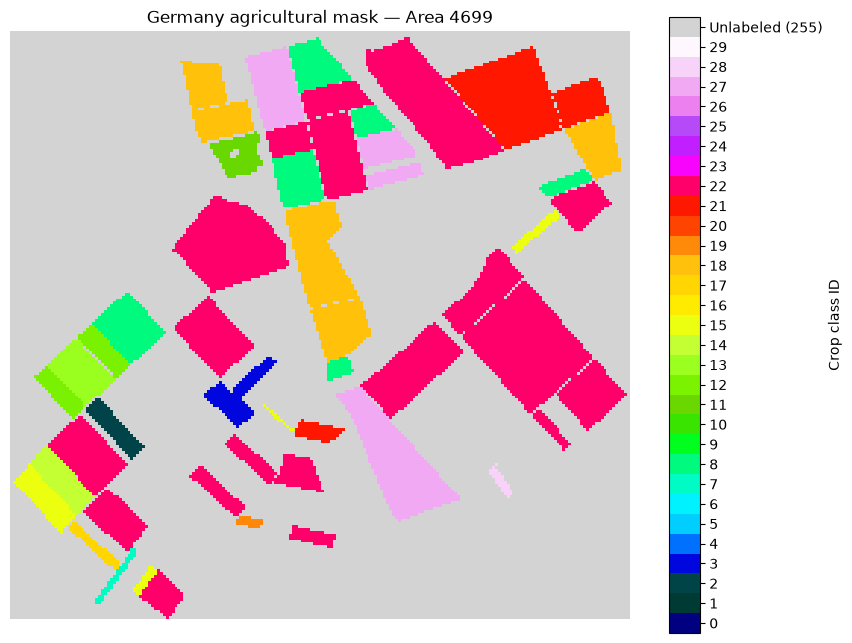

In [36]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import rasterio
import numpy as np

# Select one area
area_id = next(iter(mask_paths))
mask_path = mask_paths[area_id]

with rasterio.open(mask_path) as src:
    mask = src.read(1)

# 30 colors for crop classes 1–30
crop_colors = list(plt.cm.gist_ncar(np.linspace(0, 1, 30)))

# Grey for unlabeled pixels (255)
colors = crop_colors + ["lightgrey"]
cmap = mcolors.ListedColormap(colors)

# Replace 255 with 30 for visualization only
display_mask = mask.astype(float)
display_mask[mask == 255] = 30

# Plot
fig, ax = plt.subplots(figsize=(10, 10))

im = ax.imshow(
    display_mask,
    cmap=cmap,
    vmin=-0.5,
    vmax=30.5,
    interpolation="nearest"
)

cbar = fig.colorbar(im, ax=ax, ticks=list(range(31)), shrink=0.8)
cbar.ax.set_yticklabels(
    [str(i) for i in range(30)] + ["Unlabeled (255)"]
)
cbar.set_label("Crop class ID")

ax.set_title(f"Germany agricultural mask — Area {area_id}")
ax.axis("off")
plt.show()

## 5. Tiling into Chips

We want to take our tiles into chips so that the GPU/CPU can handle the training. 

The code below sets up our labeled crop fields with crop ids 1-30 and saves the vector files as geopackages. From these we can then create our tiles. 

In [37]:
from pathlib import Path
import geopandas as gpd

vector_dir = Path("../data/processed/vectors")
vector_dir.mkdir(parents=True, exist_ok=True)

for area_id, gdf in complete_fields_by_area.items():
    # Work on a copy and assign crop IDs
    updated_gdf = gdf.copy()
    updated_gdf["crop_id"] = updated_gdf["hcat4_name"].map(crop_mapping)

    vector_path = vector_dir / f"complete_fields_area_{area_id}.gpkg"

    # Remove the old file so there is no ambiguity about its contents
    if vector_path.exists():
        vector_path.unlink()

    # Write the updated GeoPackage
    updated_gdf.to_file(
        vector_path,
        driver="GPKG",
        layer="complete_fields",
        index=False,
    )

    # Read the saved file back and verify
    check_gdf = gpd.read_file(vector_path, layer="complete_fields")

    print(
        f"Area {area_id}: "
        f"crop_id saved = {'crop_id' in check_gdf.columns}, "
        f"missing IDs = {check_gdf['crop_id'].isna().sum()}, "
        f"file = {vector_path.resolve()}"
    )

Area 4699: crop_id saved = True, missing IDs = 0, file = /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/vectors/complete_fields_area_4699.gpkg
Area 5192: crop_id saved = True, missing IDs = 0, file = /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/vectors/complete_fields_area_5192.gpkg
Area 3712: crop_id saved = True, missing IDs = 0, file = /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/vectors/complete_fields_area_3712.gpkg
Area 10643: crop_id saved = True, missing IDs = 0, file = /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/vectors/complete_fields_area_10643.gpkg
Area 3730: crop_id saved = True, missing IDs = 0, file = /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/vectors/complete_fields_area_3730.gpkg


#### I noticed that some pixels are found in multiple crop fields. These edge pixels can mess with the training as the spectral signature is a combination of multiple crop types. Ideally we would make an edge class that the model can learn, but for now we test to see if removing them entirely and treating them as ignore (255) is sufficient. 

In [38]:
from pathlib import Path
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.features import rasterize

area_ids = [4699, 5192, 3712, 10643, 3730]

vector_dir = project_dir / "data/processed/vectors"
original_masks_dir = project_dir / "data/raw/raster"
cleaned_masks_dir = project_dir / "data/processed/masks_edge_ignored"

cleaned_masks_dir.mkdir(parents=True, exist_ok=True)

# Distance from field boundaries to ignore, in meters
boundary_width = 5.0

for area_id in area_ids:

    vector_path = vector_dir / f"complete_fields_area_{area_id}.gpkg"
    source_path = original_masks_dir / f"germany_mask_{area_id}.tif"
    output_path = cleaned_masks_dir / f"germany_mask_{area_id}.tif"

    fields = gpd.read_file(vector_path, layer="complete_fields")

    with rasterio.open(source_path) as src:
        original = src.read(1)
        profile = src.profile.copy()

        if src.crs is None or not src.crs.is_projected:
            raise ValueError(f"Expected projected CRS for area {area_id}")

        # Ensure vector and raster coordinates match
        fields = fields.to_crs(src.crs)

        # Create a 5-meter zone around every field boundary
        boundary_zones = [
            geom.boundary.buffer(boundary_width)
            for geom in fields.geometry
            if geom is not None and not geom.is_empty
        ]

        if not boundary_zones:
            raise ValueError(f"No valid field boundaries for {area_id}")

        # Rasterize boundary zones onto exactly the source mask grid
        edge_pixels = rasterize(
            ((geom, 1) for geom in boundary_zones),
            out_shape=original.shape,
            transform=src.transform,
            fill=0,
            all_touched=False,
            dtype="uint8",
        ).astype(bool)

    cleaned = original.copy()

    # Only replace currently labeled crop pixels
    crop_pixels = (original >= 1) & (original <= 30)
    pixels_to_ignore = edge_pixels & crop_pixels

    cleaned[pixels_to_ignore] = 255

    profile.update(dtype="uint8", nodata=255)

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(cleaned.astype(np.uint8), 1)

    removed = int(pixels_to_ignore.sum())
    total = int(crop_pixels.sum())
    percentage = 100 * removed / max(total, 1)

    print(
        f"Area {area_id}: ignored {removed:,} of {total:,} "
        f"crop pixels ({percentage:.1f}%)"
    )

print("Boundary-cleaned masks saved to:", cleaned_masks_dir)

Area 4699: ignored 1,712 of 13,086 crop pixels (13.1%)
Area 5192: ignored 2,800 of 19,248 crop pixels (14.5%)
Area 3712: ignored 2,905 of 20,428 crop pixels (14.2%)
Area 10643: ignored 3,621 of 25,176 crop pixels (14.4%)
Area 3730: ignored 4,186 of 25,935 crop pixels (16.1%)
Boundary-cleaned masks saved to: /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/masks_edge_ignored


#### Quick visualization

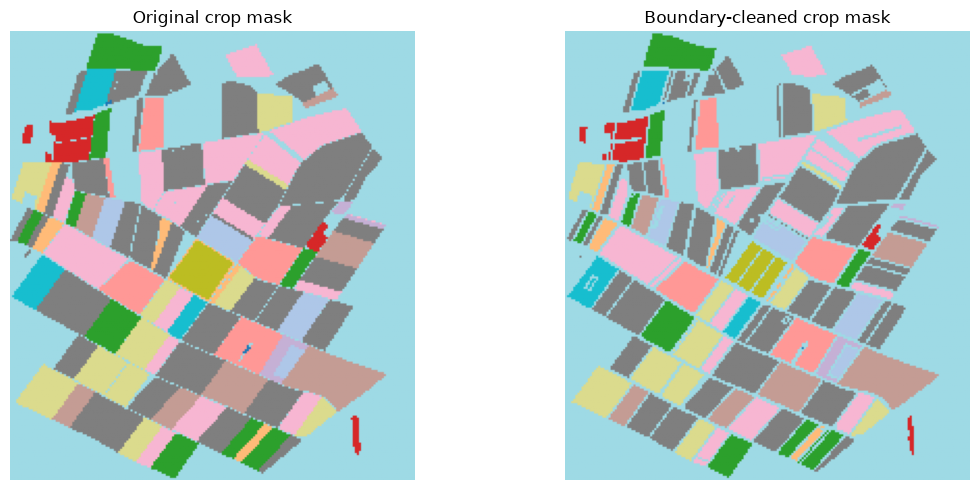

In [39]:
import matplotlib.pyplot as plt
import rasterio

area_id = 3730

original_path = original_masks_dir / f"germany_mask_{area_id}.tif"
cleaned_path = cleaned_masks_dir / f"germany_mask_{area_id}.tif"

with rasterio.open(original_path) as src:
    original = src.read(1)

with rasterio.open(cleaned_path) as src:
    cleaned = src.read(1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(original, vmin=1, vmax=30, cmap="tab20")
axes[0].set_title("Original crop mask")

axes[1].imshow(cleaned, vmin=1, vmax=30, cmap="tab20")
axes[1].set_title("Boundary-cleaned crop mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Correcting GeoAI crop id mapping. 
The GeoAI function for tile creation remaps crop ids in its own way and the labels that we gave it earlier would disappear. Therefore we patch the function so that it keeps the crop ids the way we labeled them. 

In [40]:
import numpy as np
import rasterio
from rasterio.windows import from_bounds
import geoai
import inspect

training = inspect.getmodule(geoai.export_geotiff_tiles_batch)

print("GeoAI tiling module:", training.__name__)

ALLOWED_LABEL_VALUES = {0, *range(1, 31), 255}


def load_raster_labels_preserving_ids(
    class_raster_path,
    src_crs,
    quiet=False,
    metadata_format=None,
):
    """Validate raster labels without remapping crop IDs."""

    with rasterio.open(class_raster_path) as src:
        if src.crs != src_crs:
            raise ValueError(
                f"CRS mismatch: image={src_crs}, mask={src.crs}"
            )

        data = src.read(1)
        values = set(map(int, np.unique(data)))
        unexpected = values - ALLOWED_LABEL_VALUES

        if unexpected:
            raise ValueError(
                f"Unexpected label values in {class_raster_path}: "
                f"{sorted(unexpected)}"
            )

        if not quiet:
            print(
                f"Validated {class_raster_path}: "
                f"label values = {sorted(values)}"
            )

    return {i: i for i in range(1, 31)}, []


def read_label_tile_preserving_ids(
    class_raster_path,
    minx,
    miny,
    maxx,
    maxy,
    tile_size,
    class_to_id,
):
    """Read mask pixels directly, preserving class IDs."""

    with rasterio.open(class_raster_path) as src:
        bounds = src.bounds

        if (
            minx >= bounds.right
            or maxx <= bounds.left
            or miny >= bounds.top
            or maxy <= bounds.bottom
        ):
            return (
                np.full(
                    (tile_size, tile_size),
                    255,
                    dtype=np.uint8,
                ),
                False,
            )

        window = from_bounds(
            minx,
            miny,
            maxx,
            maxy,
            transform=src.transform,
        )

        data = src.read(
            1,
            window=window,
            boundless=True,
            out_shape=(tile_size, tile_size),
            fill_value=255,
        ).astype(np.uint8, copy=False)

    # Normalize any old background pixels to ignore value 255.
    data[data == 0] = 255

    values = set(map(int, np.unique(data)))
    unexpected = values - (set(range(1, 31)) | {255})

    if unexpected:
        raise ValueError(
            f"Unexpected label values in tile: "
            f"{sorted(unexpected)}"
        )

    has_crop_pixels = bool(
        np.any((data >= 1) & (data <= 30))
    )

    return data, has_crop_pixels


# Apply the patches to GeoAI's internal functions.
training._load_class_data_raster = (
    load_raster_labels_preserving_ids
)

training._rasterize_label_from_raster = (
    read_label_tile_preserving_ids
)

print("GeoAI label-preservation patches applied.")

GeoAI tiling module: geoai.utils.training
GeoAI label-preservation patches applied.


### GENERATE: Now lets make our tiles. Our scenes are about 200 pixels so making 128 x 128 with a stride of 64 makes sense.

We are pairing them by name with the vector and raster files having the same naming structure. 

In [41]:

from pathlib import Path
import shutil
import numpy as np
import rasterio
import geoai

area_ids = [4699, 5192, 3712, 10643, 3730]

batch_images_dir = project_dir / "data/processed/batch_all/images"
batch_masks_dir = project_dir / "data/processed/batch_all/masks"
batch_output_dir = project_dir / "data/processed/batch_all"
cleaned_masks_dir = project_dir / "data/processed/masks_edge_ignored"


# Prepare fresh temporary batch output and final tiles directory.
# Original source images/masks and the old dataset directory are untouched.
if batch_output_dir.exists():
    shutil.rmtree(batch_output_dir)

batch_images_dir.mkdir(parents=True, exist_ok=True)
batch_masks_dir.mkdir(parents=True, exist_ok=True)

# Prepare all source image-mask pairs with identical filenames.
for area_id in area_ids:
    image_src = images_dir / f"germany_2023_area_{area_id}.tif"
    mask_src = cleaned_masks_dir / f"germany_mask_{area_id}.tif"

    image_dst = batch_images_dir / f"germany_2023_area_{area_id}.tif"
    mask_dst = batch_masks_dir / f"germany_2023_area_{area_id}.tif"

    if not image_src.exists() or not mask_src.exists():
        raise FileNotFoundError(
            f"Missing image or mask for area {area_id}"
        )

    with rasterio.open(image_src) as image, rasterio.open(mask_src) as mask:
        if (
            image.crs != mask.crs
            or image.transform != mask.transform
            or image.width != mask.width
            or image.height != mask.height
        ):
            raise ValueError(f"Image-mask grid mismatch for area {area_id}")

    shutil.copy2(image_src, image_dst)
    shutil.copy2(mask_src, mask_dst)

# Important: this uses the patched GeoAI functions that don't remap our crop ids.
stats_all = geoai.export_geotiff_tiles_batch(
    images_folder=str(batch_images_dir),
    masks_folder=str(batch_masks_dir),
    output_folder=str(batch_output_dir),
    tile_size=128,
    stride=64,
    match_by_name=True,
    skip_empty_tiles=False,
    metadata_format=None,
    quiet=False,
)

print("\nBatch tiling finished.")
print(stats_all)


Processing image pairs:   0%|          | 0/5 [00:00<?, ?it/s]


Batch tiling finished.
{'total_image_pairs': 5, 'processed_pairs': 5, 'total_tiles': 45, 'tiles_with_features': 45, 'errors': 0, 'processed_files': [{'image': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_all/images/germany_2023_area_10643.tif', 'mask': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_all/masks/germany_2023_area_10643.tif', 'base_name': 'germany_2023_area_10643', 'tiles_generated': 9, 'tiles_with_features': 9}, {'image': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_all/images/germany_2023_area_3712.tif', 'mask': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_all/masks/germany_2023_area_3712.tif', 'base_name': 'germany_2023_area_3712', 'tiles_generated': 9, 'tiles_with_features': 9}, {'image': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_all/images/germany_2023_area_3730.tif', 'mask': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed

#### ORGANIZE: Moving the tiles from different areas into training/validation/test split. 3 areas train, 1 validation, 1 test.

In [42]:

from pathlib import Path
import shutil
import rasterio
import numpy as np

area_ids = [4699, 5192, 3712, 10643, 3730]

split_by_area = {
    4699: "train",
    5192: "train",
    3712: "train",
    10643: "val",
    3730: "test",
}

generated_images_dir = batch_output_dir / "images"
generated_masks_dir = batch_output_dir / "masks"

final_tiles_dir = project_dir / "data/processed/tiles"
batch_output_dir = project_dir / "data/processed/batch_all"
allowed_values = set(range(1, 31)) | {255}

# Only select generated tiles, excluding full-area rasters.
generated_images = sorted(
    p for p in generated_images_dir.glob("*.tif")
    if any(
        p.name.startswith(f"germany_2023_area_{area_id}_")
        and p.stem.rsplit("_", 1)[-1].isdigit()
        for area_id in area_ids
    )
)

generated_masks = sorted(
    p for p in generated_masks_dir.glob("*.tif")
    if any(
        p.name.startswith(f"germany_2023_area_{area_id}_")
        and p.stem.rsplit("_", 1)[-1].isdigit()
        for area_id in area_ids
    )
)

image_names = {p.name for p in generated_images}
mask_names = {p.name for p in generated_masks}

if image_names != mask_names:
    raise ValueError(
        f"Image/mask mismatch. Missing masks: {image_names - mask_names}; "
        f"missing images: {mask_names - image_names}"
    )

if len(generated_images) != 45:
    raise ValueError(
        f"Expected 45 tiles based on the previous test, "
        f"but found {len(generated_images)}. Check before copying."
    )

# Recreate only the final tiles directory.
# The original data and old dataset directory remain untouched.
if final_tiles_dir.exists():
    shutil.rmtree(final_tiles_dir)

for split in ["train", "val", "test"]:
    (final_tiles_dir / split / "images").mkdir(
        parents=True, exist_ok=True
    )
    (final_tiles_dir / split / "labels").mkdir(
        parents=True, exist_ok=True
    )

counts = {"train": 0, "val": 0, "test": 0}

for image_path in generated_images:
    matching_area = next(
        area_id for area_id in area_ids
        if image_path.name.startswith(f"germany_2023_area_{area_id}_")
    )

    split = split_by_area[matching_area]
    mask_path = generated_masks_dir / image_path.name

    with rasterio.open(image_path) as image, \
         rasterio.open(mask_path) as mask:
        if (
            image.width != 128 or image.height != 128
            or mask.width != 128 or mask.height != 128
        ):
            raise ValueError(f"Unexpected tile dimensions: {image_path.name}")

        if (
            image.crs != mask.crs
            or image.transform != mask.transform
        ):
            raise ValueError(f"Image/label alignment mismatch: {image_path.name}")

        values = set(map(int, np.unique(mask.read(1))))
        invalid = values - allowed_values
        if invalid:
            raise ValueError(
                f"Unexpected label values in {mask_path.name}: {invalid}"
            )

    shutil.copy2(
        image_path,
        final_tiles_dir / split / "images" / image_path.name
    )
    shutil.copy2(
        mask_path,
        final_tiles_dir / split / "labels" / image_path.name
    )
    counts[split] += 1

print("Tiles copied successfully.")
print("Counts:", counts)
print("Total:", sum(counts.values()))
print("Output:", final_tiles_dir)


Tiles copied successfully.
Counts: {'train': 27, 'val': 9, 'test': 9}
Total: 45
Output: /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/tiles


### VALIDATE
Now as a final check we want to ensure we made tiles, that they are separated into train, validation and test tiles. And that all the images and tiles are accounted for, ensuring that image names equal label names and same for image width.  

In [43]:

allowed_values = set(range(1, 31)) | {255}
summary = {}

for split in ["train", "val", "test"]:
    image_dir = final_tiles_dir / split / "images"
    label_dir = final_tiles_dir / split / "labels"

    images = sorted(image_dir.glob("*.tif"))
    labels = sorted(label_dir.glob("*.tif"))

    image_names = {p.name for p in images}
    label_names = {p.name for p in labels}

    if image_names != label_names:
        raise ValueError(
            f"{split}: image-label filename mismatch. "
            f"Missing labels: {image_names - label_names}; "
            f"missing images: {label_names - image_names}"
        )

    for image_path in images:
        label_path = label_dir / image_path.name

        with rasterio.open(image_path) as image, \
             rasterio.open(label_path) as label:
            if (
                image.width != label.width
                or image.height != label.height
                or image.crs != label.crs
                or image.transform != label.transform
            ):
                raise ValueError(
                    f"Grid mismatch in {split}: {image_path.name}"
                )

            values = set(map(int, np.unique(label.read(1))))
            invalid = values - allowed_values

            if invalid:
                raise ValueError(
                    f"Unexpected label IDs in {label_path.name}: "
                    f"{sorted(invalid)}"
                )

    summary[split] = len(images)

expected_counts = {"train": 27, "val": 9, "test": 9} ### Defensive coding

if summary != expected_counts:
    raise ValueError(
        f"Unexpected tile counts: {summary}. "
        f"Expected: {expected_counts}"
    )

print("Final tile counts:", summary)
print("Total tiles:", sum(summary.values()))
print("All image-label pairs and label IDs validated.")


Final tile counts: {'train': 27, 'val': 9, 'test': 9}
Total tiles: 45
All image-label pairs and label IDs validated.



from pathlib import Path
from collections import Counter

import numpy as np
import rasterio
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader


In [44]:

tiles_dir = project_dir / "data/processed/tiles"
splits = ["train", "val", "test"]

class_names = {
    1: "alfalfa_lucerne",
    2: "asparagus",
    3: "beans",
    4: "buckwheat",
    5: "carrots_daucus",
    6: "clover",
    7: "lupins",
    8: "maize_corn_popcorn",
    9: "miscanthus_silvergrass",
    10: "peas",
    11: "permanent_grassland",
    12: "potatoes",
    13: "soy_soybeans",
    14: "spring_barley",
    15: "spring_common_soft_wheat",
    16: "spring_oats",
    17: "strawberries",
    18: "sugar_beet",
    19: "sunflower",
    20: "temporary_grassland",
    21: "winter_barley",
    22: "winter_common_soft_wheat",
    23: "winter_durum_hard_wheat",
    24: "winter_emmer",
    25: "winter_mixed_grains",
    26: "winter_oats",
    27: "winter_rapeseed_rape",
    28: "winter_rye",
    29: "winter_spelt",
    30: "winter_triticale",
}

pixel_counts = {split: Counter() for split in splits}

for split in splits:
    label_dir = tiles_dir / split / "labels"

    for label_path in sorted(label_dir.glob("*.tif")):
        with rasterio.open(label_path) as src:
            mask = src.read(1)

        values, counts = np.unique(mask, return_counts=True)
        for value, count in zip(values, counts):
            pixel_counts[split][int(value)] += int(count)

for split in splits:
    labeled_pixels = sum(
        count for label, count in pixel_counts[split].items()
        if 1 <= label <= 30
    )
    ignored_pixels = pixel_counts[split].get(255, 0)

    print(f"\n{split.upper()}")
    print("Crop-labeled pixels:", f"{labeled_pixels:,}")
    print("Ignored pixels (255):", f"{ignored_pixels:,}")
    print("Crop classes present:", sum(
        pixel_counts[split].get(i, 0) > 0 for i in range(1, 31)
    ))


NameError: name 'Counter' is not defined

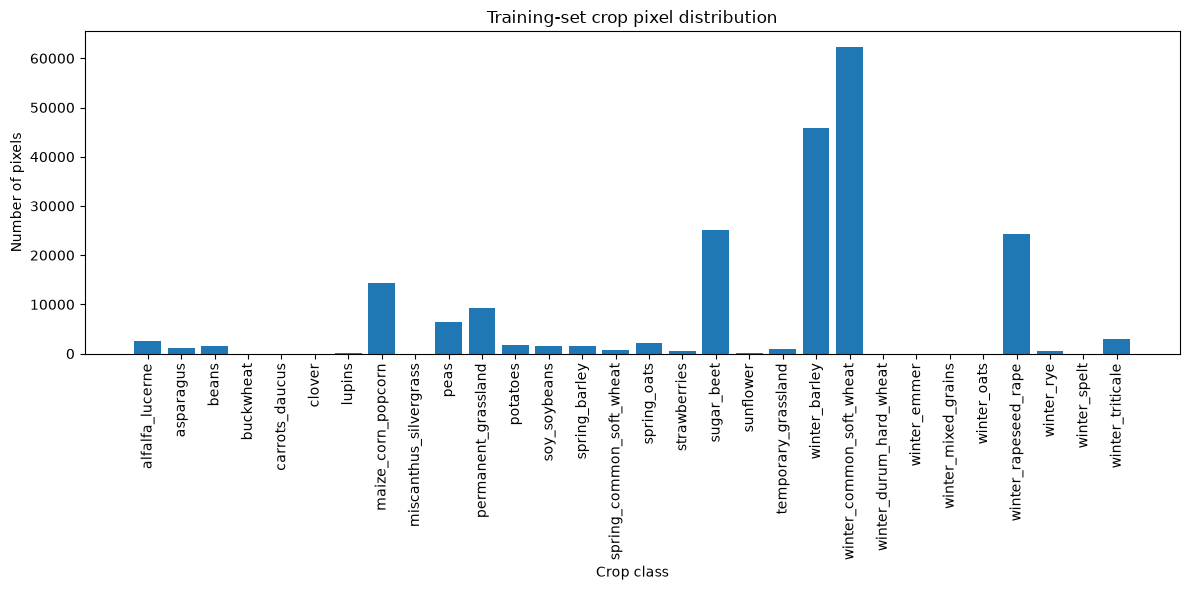

In [ ]:

train_counts = [
    pixel_counts["train"].get(class_id, 0)
    for class_id in range(1, 31)
]

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(
    [class_names[i] for i in range(1, 31)],
    train_counts
)
ax.set_title("Training-set crop pixel distribution")
ax.set_xlabel("Crop class")
ax.set_ylabel("Number of pixels")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
plt.show()


## 6. Model training

### Prepare training and validation datasets

In [ ]:
from pathlib import Path
import shutil
import numpy as np
import rasterio

tiles_dir = project_dir / "data/processed/tiles"
geoai_input_dir = project_dir / "data/processed/geoai_training_input"

# Only recreate the dedicated GeoAI staging folder.
if geoai_input_dir.exists():
    shutil.rmtree(geoai_input_dir)

stage_images = geoai_input_dir / "images"
stage_labels = geoai_input_dir / "labels"

stage_images.mkdir(parents=True)
stage_labels.mkdir(parents=True)

split_names = {"train": set(), "val": set()}

for split in ["train", "val"]:
    image_dir = tiles_dir / split / "images"
    label_dir = tiles_dir / split / "labels"

    images = sorted(image_dir.glob("*.tif"))
    labels = sorted(label_dir.glob("*.tif"))

    assert {p.name for p in images} == {p.name for p in labels}

    for image_path in images:
        name = image_path.name

        # Distinct area IDs guarantee non-overlapping split membership.
        expected_ids = (
            [4699, 5192, 3712] if split == "train" else [10643]
        )
        assert any(
            name.startswith(f"germany_2023_area_{area_id}_")
            for area_id in expected_ids
        ), f"Unexpected {split} tile: {name}"

        with rasterio.open(image_path) as src:
            image = src.read().astype(np.float32)
            image_profile = src.profile.copy()

        with rasterio.open(label_dir / name) as src:
            labels_array = src.read(1)
            label_profile = src.profile.copy()

        assert image.shape[0] == 4
        assert np.all(
            ((labels_array >= 1) & (labels_array <= 30))
            | (labels_array == 255)
        )

        # GeoAI divides images by 255 when loading.
        # Convert Sentinel-2 scaled reflectance into that range.
        # Assumes original values use the 10,000 reflectance scale.
        image = np.clip(image / 10000.0, 0, 1) * 255.0

        image_profile.update(dtype="float32")
        with rasterio.open(stage_images / name, "w", **image_profile) as dst:
            dst.write(image)

        # Model classes 0–29, with 255 still ignored.
        valid = labels_array != 255
        labels_array = labels_array.copy()
        labels_array[valid] -= 1

        label_profile.update(dtype="uint8", nodata=255)
        with rasterio.open(stage_labels / name, "w", **label_profile) as dst:
            dst.write(labels_array.astype(np.uint8), 1)

        split_names[split].add(name)

assert len(split_names["train"]) == 27
assert len(split_names["val"]) == 9
assert split_names["train"].isdisjoint(split_names["val"])

print("Training tiles:", len(split_names["train"]))
print("Validation tiles:", len(split_names["val"]))
print("Test tiles used: 0")
print("GeoAI inputs prepared.")

Training tiles: 27
Validation tiles: 9
Test tiles used: 0
GeoAI inputs prepared.


#### Adding weights to our crop classes in an inverse square root proportion. These treats rarer classes with more weight. 

In [ ]:
import numpy as np
import rasterio

train_labels_dir = project_dir / "data/processed/tiles/train/labels"

# Original crop IDs are 1–30.
counts = np.zeros(30, dtype=np.int64)

for label_path in sorted(train_labels_dir.glob("*.tif")):
    with rasterio.open(label_path) as src:
        mask = src.read(1)

    valid = (mask >= 1) & (mask <= 30)

    counts += np.bincount(
        mask[valid].astype(int) - 1,
        minlength=30
    )

# Use inverse square-root frequencies.
# This weights rare classes more without being too extreme.
present = counts > 0

weights = np.ones(30, dtype=np.float64)

weights[present] = 1 / np.sqrt(counts[present])

# Normalize so the average weight of present classes is 1.
weights[present] /= weights[present].mean()

# Prevent extremely rare classes receiving excessive weights.
weights[present] = np.clip(weights[present], 0.2, 5.0)

# Classes absent from training get neutral weights.
weights[~present] = 1.0

class_weights = weights.tolist()

print("Classes present in training:", present.sum(), "/ 30")

for crop_id in range(1, 31):
    print(
        f"Crop {crop_id:2d}: "
        f"{counts[crop_id - 1]:>8,} pixels, "
        f"weight = {weights[crop_id - 1]:.3f}"
    )

Classes present in training: 21 / 30
Crop  1:    2,054 pixels, weight = 0.439
Crop  2:      842 pixels, weight = 0.686
Crop  3:    1,241 pixels, weight = 0.565
Crop  4:        0 pixels, weight = 1.000
Crop  5:        0 pixels, weight = 1.000
Crop  6:        0 pixels, weight = 1.000
Crop  7:       45 pixels, weight = 2.966
Crop  8:   12,347 pixels, weight = 0.200
Crop  9:        0 pixels, weight = 1.000
Crop 10:    5,704 pixels, weight = 0.263
Crop 11:    7,016 pixels, weight = 0.238
Crop 12:    1,527 pixels, weight = 0.509
Crop 13:    1,314 pixels, weight = 0.549
Crop 14:      792 pixels, weight = 0.707
Crop 15:      468 pixels, weight = 0.920
Crop 16:    1,912 pixels, weight = 0.455
Crop 17:      426 pixels, weight = 0.964
Crop 18:   21,702 pixels, weight = 0.200
Crop 19:       84 pixels, weight = 2.171
Crop 20:        7 pixels, weight = 5.000
Crop 21:   39,672 pixels, weight = 0.200
Crop 22:   54,825 pixels, weight = 0.200
Crop 23:        0 pixels, weight = 1.000
Crop 24:        0 pi

#### Now finally train our first model!

In [ ]:
import geoai
import inspect
import torch

train_fn = inspect.unwrap(geoai.train_segmentation_model)
scope = train_fn.__globals__

assert "train_test_split" in scope, (
    "GeoAI's split implementation has changed. "
    "Check the installed version before training."
)

original_split = scope["train_test_split"]


def geographic_split(image_files, label_files, **kwargs):
    """Use the existing geographic split instead of a random split."""

    assert len(image_files) == len(label_files)

    pairs = list(zip(image_files, label_files))

    for image_path, label_path in pairs:
        assert Path(image_path).name == Path(label_path).name

    train_pairs = [
        pair for pair in pairs
        if Path(pair[0]).name in split_names["train"]
    ]
    val_pairs = [
        pair for pair in pairs
        if Path(pair[0]).name in split_names["val"]
    ]

    assert len(train_pairs) == 27
    assert len(val_pairs) == 9
    assert len(train_pairs) + len(val_pairs) == len(pairs)

    print("Fixed geographic split: 27 train, 9 validation")

    return (
        [p[0] for p in train_pairs],
        [p[0] for p in val_pairs],
        [p[1] for p in train_pairs],
        [p[1] for p in val_pairs],
    )


model_dir = project_dir / "models/unet_geoai_imagenet_cropweighted"
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

try:
    scope["train_test_split"] = geographic_split

    result = geoai.train_segmentation_model(
        images_dir=str(stage_images),
        labels_dir=str(stage_labels),
        output_dir=str(model_dir),
        architecture="unet",
        encoder_name="resnet18",
        encoder_weights="imagenet",
        class_weights=class_weights,
        num_channels=4,
        num_classes=30,
        batch_size=3,
        num_epochs=10,
        learning_rate=0.001,
        val_split=0.25,  # Replaced by our geographic split patch
        ignore_index=255,
        num_workers=0,
        device=device,
        verbose=True,
        plot_curves=True,
    )

finally:
    scope["train_test_split"] = original_split

print("Training finished.")
print("Model directory:", model_dir)

Fixed geographic split: 27 train, 9 validation
Training finished.
Model directory: /Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_geoai_imagenet_cropweighted


#### The model works! Its probably not very good though.

## 7. Model evaluation

#### Plot training performance

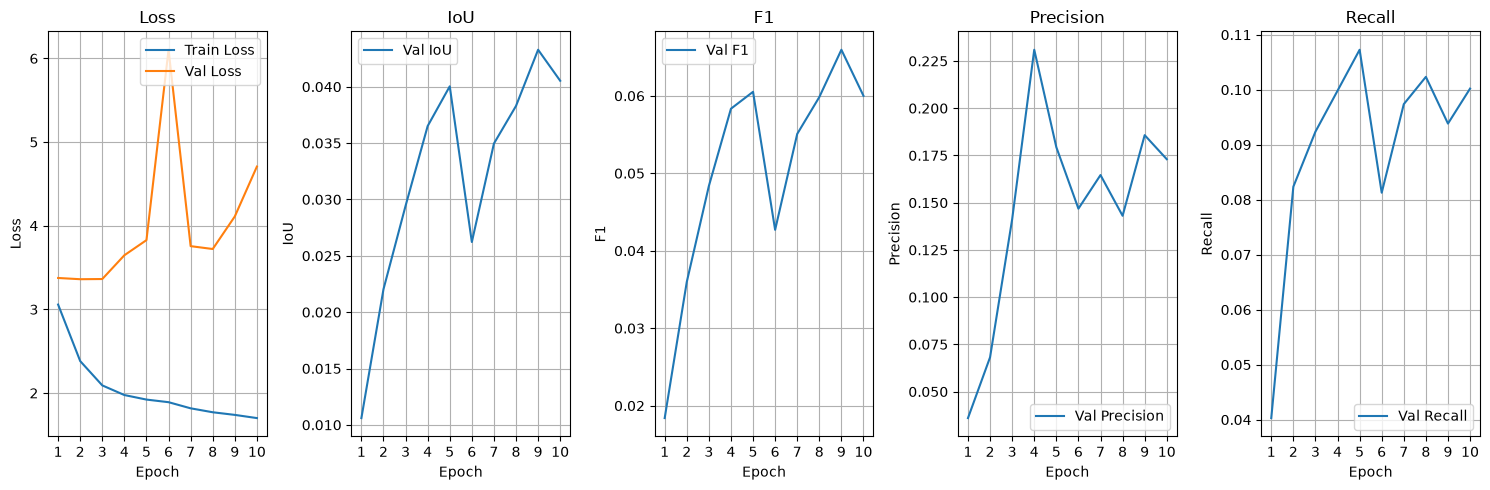

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,3.057416,3.375204,0.010604,0.018397,0.035991,0.040287
1,2,2.381779,3.360346,0.022037,0.035971,0.068174,0.082367
2,3,2.091132,3.362657,0.029435,0.048353,0.141192,0.092374
3,4,1.975886,3.646781,0.036511,0.058337,0.230937,0.099816
4,5,1.921605,3.827579,0.040037,0.060517,0.179376,0.107270
5,6,1.890404,6.103285,0.026222,0.042697,0.146832,0.081268
6,7,1.817125,3.755630,0.034960,0.055081,0.164620,0.097381
7,8,1.770054,3.721417,0.038297,0.059840,0.143056,0.102340
8,9,1.738562,4.110939,0.043281,0.065948,0.185739,0.093841
9,10,1.700448,4.706870,0.040529,0.060000,0.173005,0.100204


In [ ]:
import geoai

model_dir = project_dir / "models/unet_geoai_imagenet_cropweighted"

geoai.plot_performance_metrics(
    history_path=str(model_dir / "training_history.pth"),
    figsize=(15, 5),
    verbose=True,
)

The model is overfitting, as train loss decreases as validation loss increases. Also IoU is lower in epoch 10 than epoch 1.

#### Create predictions of crop type of validation tiles

In [ ]:
from pathlib import Path
import rasterio
import numpy as np
import torch

model_dir = project_dir / "models/unet_geoai_imagenet_cropweighted"
model_path = model_dir / "best_model.pth"

val_images_dir = (
    project_dir / "data/processed/geoai_training_input/images"
)

val_labels_dir = (
    project_dir / "data/processed/tiles/val/labels"
)

predictions_dir = model_dir / "validation_predictions"
predictions_dir.mkdir(parents=True, exist_ok=True)

val_images = sorted(
    p for p in val_images_dir.glob("germany_2023_area_10643_*.tif")
    if p.stem.rsplit("_", 1)[-1].isdigit()
)

assert model_path.exists(), f"Model not found: {model_path}"
assert len(val_images) == 9, (
    f"Expected 9 validation tiles, found {len(val_images)}"
)

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

for image_path in val_images:
    output_path = predictions_dir / image_path.name

    geoai.semantic_segmentation(
        input_path=str(image_path),
        output_path=str(output_path),
        model_path=str(model_path),
        architecture="unet",
        encoder_name="resnet18",
        num_channels=4,
        num_classes=30,
        window_size=128,
        overlap=0,
        batch_size=1,
        device=device,
        quiet=True,
    )

print(f"Predictions created: {len(val_images)}")
print("Saved to:", predictions_dir)

Predictions created: 9
Saved to: /Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_geoai_imagenet_cropweighted/validation_predictions


#### Calculate pixel accuracy and IoU

In [ ]:
confusion = np.zeros((30, 30), dtype=np.int64)

for image_path in val_images:
    label_path = val_labels_dir / image_path.name
    prediction_path = predictions_dir / image_path.name

    with rasterio.open(label_path) as src:
        truth = src.read(1)

    with rasterio.open(prediction_path) as src:
        prediction = src.read(1).astype(np.int64)

    assert prediction.shape == truth.shape
    assert np.all((prediction >= 0) & (prediction < 30))

    # Evaluate crop pixels only; ignore background and boundaries.
    valid = (truth >= 1) & (truth <= 30)

    actual = truth[valid].astype(np.int64) - 1
    predicted = prediction[valid]

    confusion += np.bincount(
        30 * actual + predicted,
        minlength=30 * 30
    ).reshape(30, 30)

intersection = np.diag(confusion)
actual_count = confusion.sum(axis=1)
predicted_count = confusion.sum(axis=0)
union = actual_count + predicted_count - intersection

present = actual_count > 0
iou = np.divide(
    intersection, union,
    out=np.zeros(30, dtype=float),
    where=union > 0
)

pixel_accuracy = intersection.sum() / max(confusion.sum(), 1)
mean_iou = iou[present].mean()

print(f"Validation pixel accuracy: {pixel_accuracy:.2%}")
print(f"Validation mean IoU:       {mean_iou:.2%}")
print(f"Crop classes in validation: {present.sum()} / 30")

print("\nPer-class IoU (original crop IDs):")
for crop_id in range(1, 31):
    if present[crop_id - 1]:
        print(f"Crop {crop_id:2d}: {iou[crop_id - 1]:.2%}")

Validation pixel accuracy: 20.68%
Validation mean IoU:       4.90%
Crop classes in validation: 17 / 30

Per-class IoU (original crop IDs):
Crop  1: 0.00%
Crop  3: 0.00%
Crop  6: 0.00%
Crop  8: 49.74%
Crop 10: 0.00%
Crop 11: 1.54%
Crop 12: 0.00%
Crop 13: 0.00%
Crop 14: 0.00%
Crop 17: 0.00%
Crop 20: 0.00%
Crop 21: 11.66%
Crop 22: 17.34%
Crop 27: 3.06%
Crop 28: 0.00%
Crop 29: 0.00%
Crop 30: 0.00%


Pixel accuracy is low, 27.72%. Also IoU is extremely low even for the crops. 

#### Visualize a prediction

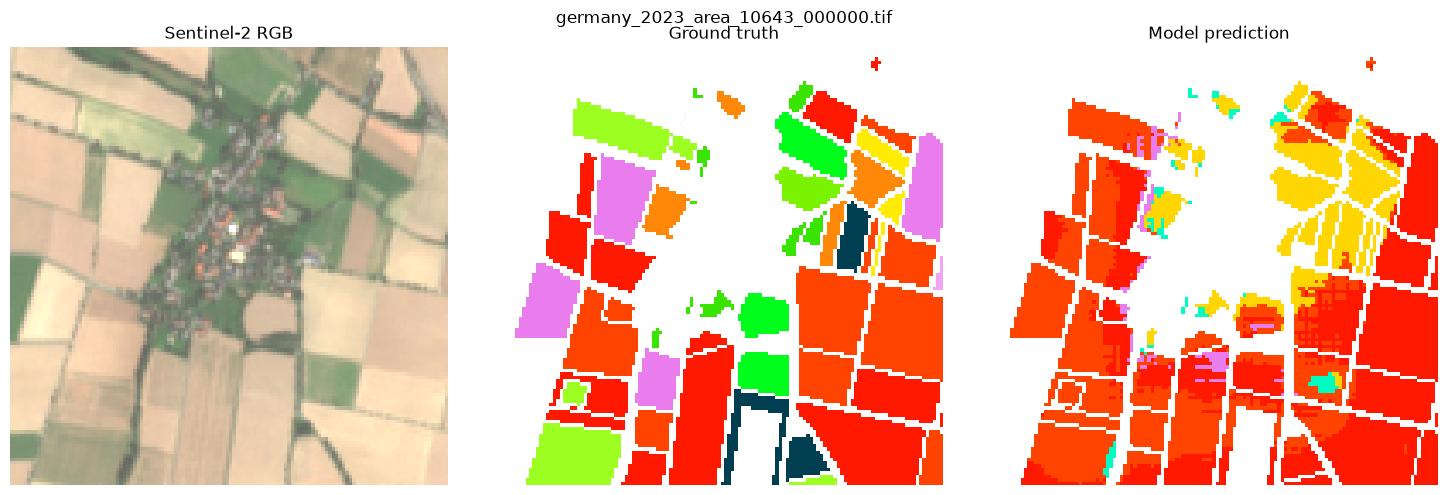

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

image_path = val_images[0]

original_image_path = (
    project_dir / "data/processed/tiles/val/images"
    / image_path.name
)

with rasterio.open(original_image_path) as src:
    image = src.read().astype(np.float32)

with rasterio.open(val_labels_dir / image_path.name) as src:
    truth = src.read(1)

with rasterio.open(predictions_dir / image_path.name) as src:
    prediction = src.read(1).astype(np.int64) + 1

# Assumes band order B2, B3, B4, B8.
rgb = np.moveaxis(image[[2, 1, 0]], 0, -1)
rgb = np.clip(rgb / 3000.0, 0, 1)

colors = plt.get_cmap("gist_ncar", 30)(
    np.arange(30)
)
cmap = ListedColormap(colors)
cmap.set_bad("white")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(rgb)
axes[0].set_title("Sentinel-2 RGB")

axes[1].imshow(
    np.ma.masked_equal(truth, 255),
    cmap=cmap, vmin=0.5, vmax=30.5
)
axes[1].set_title("Ground truth")

axes[2].imshow(
    np.ma.masked_where(truth == 255, prediction),
    cmap=cmap, vmin=0.5, vmax=30.5
)
axes[2].set_title("Model prediction")

for ax in axes:
    ax.axis("off")

plt.suptitle(image_path.name)
plt.tight_layout()
plt.show()

The image shows the prediction of crop types from a semantic segmentation model of a small 2 by 2 km field in Germany. It compares the ground truth (middle) to the model prediction (right). The model struggles to identify between different crop types, likely because many of them are rare and there are a few crop types which heavily dominate the training dataset. However it is able to delineate between crop fields which is pretty neat. 

#### It is likely that the strong class imbalance makes training difficult. Ideally we see what classes the model predicts too frequently.

In [ ]:
import numpy as np
import rasterio
from collections import Counter

true_counts = Counter()
pred_counts = Counter()

for image_path in val_images:
    with rasterio.open(val_labels_dir / image_path.name) as src:
        truth = src.read(1)

    with rasterio.open(predictions_dir / image_path.name) as src:
        prediction = src.read(1).astype(np.int64) + 1

    # Only compare pixels with a valid ground-truth crop label
    valid = (truth >= 1) & (truth <= 30)

    true_counts.update(truth[valid].tolist())
    pred_counts.update(prediction[valid].tolist())

print("Most common true crop classes:")
print(true_counts.most_common(10))

print("\nMost common predicted crop classes:")
print(pred_counts.most_common(10))

Most common true crop classes:
[(22, 21198), (21, 17040), (27, 13095), (10, 6913), (14, 6313), (28, 5779), (8, 5387), (3, 3537), (30, 2079), (29, 2040)]

Most common predicted crop classes:
[(22, 36186), (21, 32379), (18, 10737), (8, 8385), (27, 2627), (1, 118), (11, 68)]
